In [1]:
import os
from collections import Counter

ROOT = '/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset'   # paste your real path

ext = Counter()
for r, d, f in os.walk(ROOT):
    if r.count(os.sep) - ROOT.count(os.sep) <= 2:
        print(r, '->', d[:6], len(f), 'files')
    for x in f:
        ext[os.path.splitext(x)[1].lower()] += 1
print(ext)

/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset -> ['train'] 3 files
/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset/train -> ['labels', 'images'] 0 files
/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset/train/labels -> [] 58 files
/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset/train/images -> [] 58 files
Counter({'.txt': 60, '.jpg': 58, '.yaml': 1})


data.yaml found: ['/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset/data.yaml']
classes: ['acne', 'acne_scar', 'dark_spot', 'pimple']
label files: 58
sample label line: ['1 0.265625 0.54375 0.03671875 0.02578125']
boxes per class: {'acne_scar': 116, 'dark_spot': 184, 'acne': 53, 'pimple': 2}
acne_scar : 116 crops


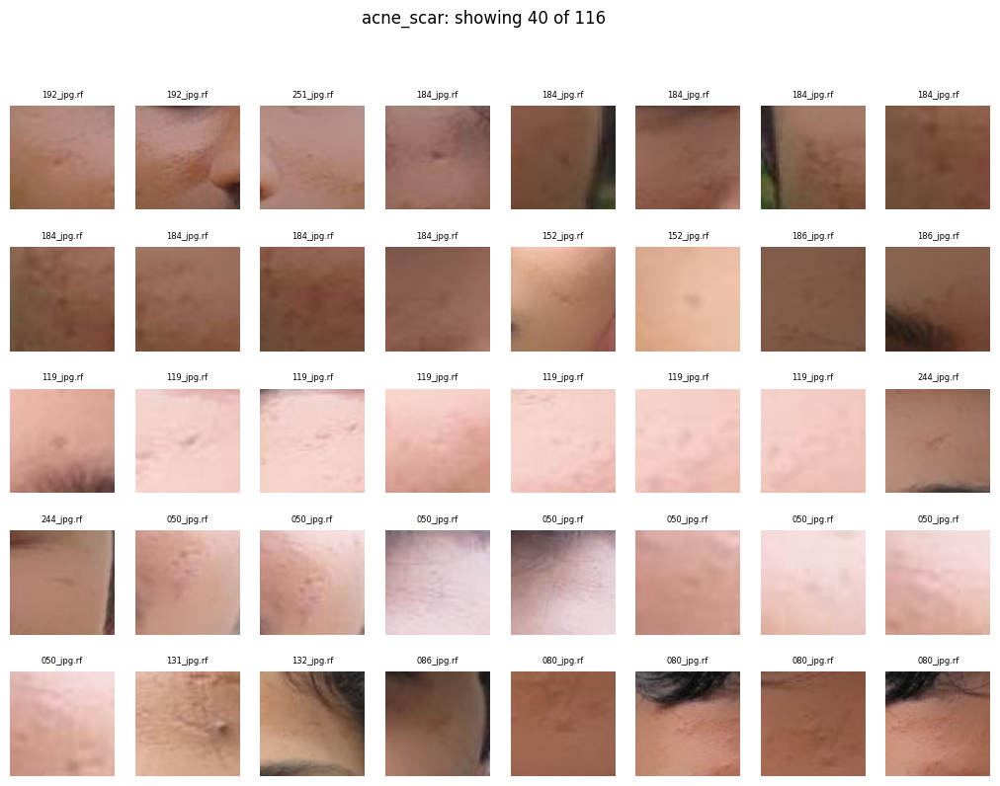

acne : 53 crops


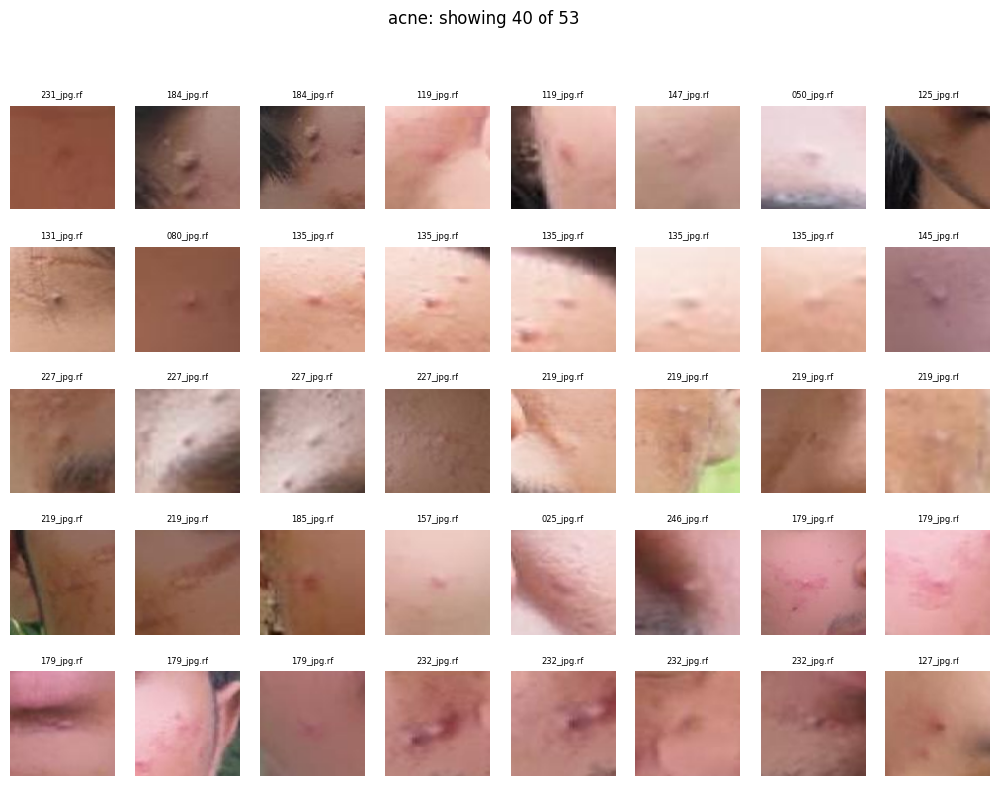

pimple : 2 crops


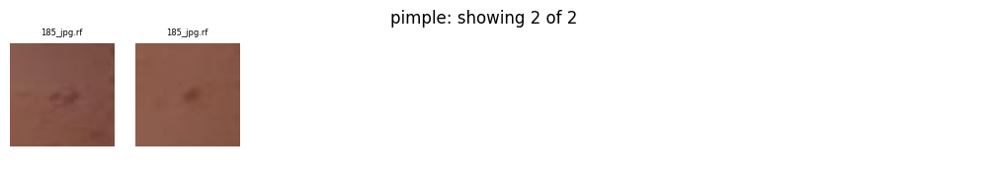

scars : 0 crops


In [2]:
import glob, yaml
from PIL import Image
import matplotlib.pyplot as plt

yaml_files = glob.glob(f'{ROOT}/**/data.yaml', recursive=True)
print('data.yaml found:', yaml_files)
assert yaml_files, 'No data.yaml: maybe not a YOLO export (see Step 2 file types)'
names = yaml.safe_load(open(yaml_files[0]))['names']
if isinstance(names, dict): names = [names[k] for k in sorted(names)]
print('classes:', names)

label_files = glob.glob(f'{ROOT}/**/labels/*.txt', recursive=True)
print('label files:', len(label_files))
assert label_files, 'No label .txt files found: check Step 2 output'
print('sample label line:', open(label_files[0]).read().splitlines()[:1])

want = {'acne', 'pimple', 'acne_scar', 'scars'}
crops = {n: [] for n in want}
counts = {}
for lbl in label_files:
    stem = os.path.splitext(os.path.basename(lbl))[0]
    img_dir = os.path.join(os.path.dirname(os.path.dirname(lbl)), 'images')
    matches = glob.glob(os.path.join(img_dir, stem + '.*'))
    if not matches: continue
    img = Image.open(matches[0]).convert('RGB'); W, H = img.size
    for line in open(lbl).read().strip().splitlines():
        p = line.split()
        if len(p) < 5: continue
        n = names[int(p[0])]
        counts[n] = counts.get(n, 0) + 1
        if n not in want: continue
        cx, cy, w, h = float(p[1])*W, float(p[2])*H, float(p[3])*W, float(p[4])*H
        pad = max(w, h)                       # include surrounding skin
        box = (int(cx-w/2-pad), int(cy-h/2-pad), int(cx+w/2+pad), int(cy+h/2+pad))
        crops[n].append((os.path.basename(matches[0]), img.crop(box).resize((128, 128))))

print('boxes per class:', counts)
for n, items in crops.items():
    print(n, ':', len(items), 'crops')
    if not items: continue
    total, items = len(items), items[:40]
    cols = 8; rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*1.6, rows*1.8), squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (fn, im) in zip(axes.ravel(), items):
        ax.imshow(im); ax.set_title(fn[:10], fontsize=6)
    fig.suptitle(f'{n}: showing {len(items)} of {total}')
    plt.show()

In [3]:

import os
from collections import Counter
from glob import glob
import yaml

ROOT = (
    '/kaggle/input/datasets/malgamage/'
    'acne-marks-dataset-computer-vision-dataset'
)

with open(os.path.join(ROOT, 'data.yaml')) as f:
    names = yaml.safe_load(f)['names']

if isinstance(names, dict):
    names = [names[k] for k in sorted(names)]

label_files = glob(
    os.path.join(ROOT, 'train', 'labels', '*.txt')
)

# Initial research grouping only; verify labels before merging.
active_names = {'acne', 'pimple'}
scar_names = {'acne_scar'}

summary = Counter()
both_images = []
per_image = []

for label_path in sorted(label_files):
    present = set()

    with open(label_path) as f:
        for line in f:
            parts = line.split()
            if len(parts) < 5:
                continue

            class_id = int(parts[0])
            class_name = names[class_id]
            present.add(class_name)

    has_active = bool(present & active_names)
    has_scar = bool(present & scar_names)

    if has_active and has_scar:
        category = 'Both active acne and scars'
        both_images.append(os.path.basename(label_path)[:-4])
    elif has_active:
        category = 'Active acne only'
    elif has_scar:
        category = 'Scars only'
    else:
        category = 'Neither target class'

    summary[category] += 1
    per_image.append({
        'image': os.path.basename(label_path)[:-4],
        'category': category,
        'classes': sorted(present)
    })

print('IMAGE-LEVEL SUMMARY')
for category in [
    'Both active acne and scars',
    'Active acne only',
    'Scars only',
    'Neither target class'
]:
    print(f'{category}: {summary[category]}')

print('\nIMAGES CONTAINING BOTH CLASSES')
for image_id in both_images:
    print(image_id)

print('\nALL IMAGE LABELS')
for row in per_image:
    print(row)


IMAGE-LEVEL SUMMARY
Both active acne and scars: 14
Active acne only: 11
Scars only: 23
Neither target class: 10

IMAGES CONTAINING BOTH CLASSES
025_jpg.rf.1d3939f4349e9f01e1eb4d043c544e04
050_jpg.rf.bfa1fce8146fd0dc82bb3ac7ceff4572
053_jpg.rf.663920c1fe83c2f36f2a084e30b3b1f5
080_jpg.rf.dfea08787bea5fa16b0fda264a732628
119_jpg.rf.2cb9ca0a44ba93d4dbad4c736acf9e2a
124_jpg.rf.46b61c630ed8c539047937f5c194b0d1
131_jpg.rf.02faa957bd33a59bda49982f7c6d0e9a
133_jpg.rf.90da0b73e54a3466a55fdb5245bd90f4
145_jpg.rf.8f22c48ffbd9cca93d1b73e1d95f7535
179_jpg.rf.f248171734a84122228f7967fb9aaef9
184_jpg.rf.687891ee3b05277159a87bb44ab91853
185_jpg.rf.3b7e7fbf6fcfce81fb6e4201a4069562
227_jpg.rf.4216daf1bfa998c8ac52f66ede812bf7
232_jpg.rf.c35cbea9e7ef260f46ce09bfb48d901d

ALL IMAGE LABELS
{'image': '018_jpg.rf.5e5de9f22873855ad5afd2a6e3bf399e', 'category': 'Neither target class', 'classes': ['dark_spot']}
{'image': '025_jpg.rf.1d3939f4349e9f01e1eb4d043c544e04', 'category': 'Both active acne and scars', 'cla

Classes: ['acne', 'acne_scar', 'dark_spot', 'pimple']

Found 14 images containing both classes.


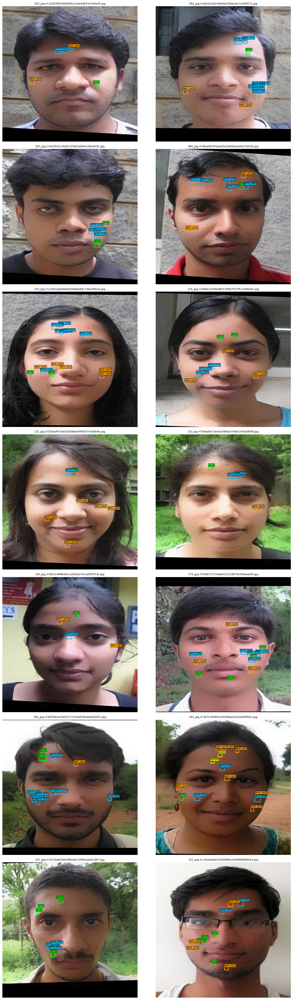

In [4]:

import os
import glob
import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = (
    '/kaggle/input/datasets/malgamage/'
    'acne-marks-dataset-computer-vision-dataset'
)

IMG_DIR = os.path.join(ROOT, 'train', 'images')
LBL_DIR = os.path.join(ROOT, 'train', 'labels')

# Load YOLO class names
with open(os.path.join(ROOT, 'data.yaml')) as f:
    names = yaml.safe_load(f)['names']

if isinstance(names, dict):
    names = [names[k] for k in sorted(names)]

print("Classes:", names)

# Find images containing BOTH target classes
target_classes = {'acne', 'acne_scar'}
selected = []

for label_path in sorted(glob.glob(os.path.join(LBL_DIR, '*.txt'))):
    present = set()

    with open(label_path) as f:
        for line in f:
            parts = line.split()
            if len(parts) >= 5:
                present.add(names[int(parts[0])])

    if target_classes.issubset(present):
        stem = os.path.splitext(os.path.basename(label_path))[0]
        matches = glob.glob(os.path.join(IMG_DIR, stem + '.*'))

        if matches:
            selected.append((matches[0], label_path))

print(f"\nFound {len(selected)} images containing both classes.")

# Colours for displaying the annotations
class_colours = {
    'acne': 'lime',
    'acne_scar': 'deepskyblue',
    'dark_spot': 'orange',
    'pimple': 'yellow'
}

# Display all selected images
cols = 2
rows = (len(selected) + cols - 1) // cols

fig, axes = plt.subplots(
    rows, cols,
    figsize=(14, rows * 6),
    squeeze=False
)

for ax in axes.ravel():
    ax.axis('off')

for ax, (img_path, label_path) in zip(axes.ravel(), selected):
    img = Image.open(img_path).convert('RGB')
    W, H = img.size

    ax.imshow(img)
    ax.axis('off')
    ax.set_title(os.path.basename(img_path), fontsize=8)

    with open(label_path) as f:
        for line in f:
            p = line.split()
            if len(p) < 5:
                continue

            cls_id = int(p[0])
            cls_name = names[cls_id]

            # YOLO: normalized centre x, centre y, width, height
            cx, cy, bw, bh = map(float, p[1:5])

            x = (cx - bw / 2) * W
            y = (cy - bh / 2) * H
            box_w = bw * W
            box_h = bh * H

            colour = class_colours.get(cls_name, 'white')

            rect = patches.Rectangle(
                (x, y), box_w, box_h,
                linewidth=1.8,
                edgecolor=colour,
                facecolor='none'
            )
            ax.add_patch(rect)

            ax.text(
                x, max(0, y - 3),
                cls_name,
                color='black',
                fontsize=7,
                bbox=dict(facecolor=colour, alpha=0.85, pad=1)
            )

for ax in axes.ravel()[len(selected):]:
    ax.axis('off')

plt.tight_layout()
plt.show()


Found 14 images containing both classes.


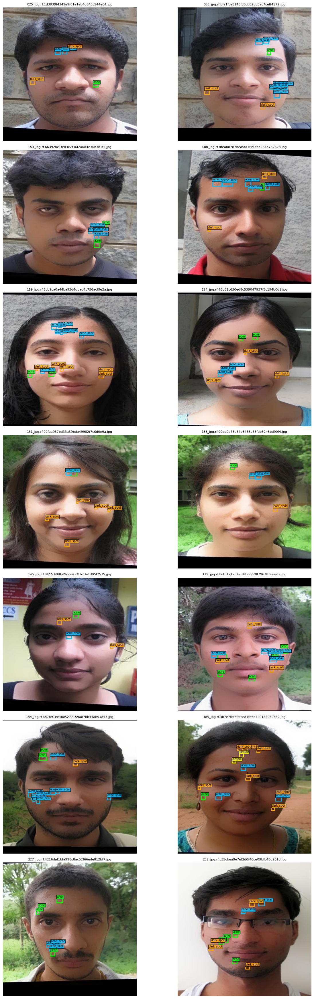

In [5]:

import os
import glob
import yaml
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

ROOT = '/kaggle/input/datasets/malgamage/acne-marks-dataset-computer-vision-dataset'
IMG_DIR = os.path.join(ROOT, 'train', 'images')
LBL_DIR = os.path.join(ROOT, 'train', 'labels')

with open(os.path.join(ROOT, 'data.yaml')) as f:
    names = yaml.safe_load(f)['names']

if isinstance(names, dict):
    names = [names[k] for k in sorted(names)]

# Find images containing both acne and acne_scar
selected = []

for label_path in sorted(glob.glob(os.path.join(LBL_DIR, '*.txt'))):
    with open(label_path) as f:
        lines = f.read().splitlines()

    present = {
        names[int(line.split()[0])]
        for line in lines
        if len(line.split()) >= 5
    }

    if {'acne', 'acne_scar'}.issubset(present):
        stem = os.path.splitext(os.path.basename(label_path))[0]
        matches = glob.glob(os.path.join(IMG_DIR, stem + '.*'))

        if matches:
            selected.append((matches[0], label_path))

print(f'Found {len(selected)} images containing both classes.')

colours = {
    'acne': 'lime',
    'acne_scar': 'deepskyblue',
    'dark_spot': 'orange',
    'pimple': 'yellow'
}

# Display all 14 images with annotations
cols = 2
rows = (len(selected) + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 5))
axes = axes.ravel()

for ax in axes:
    ax.axis('off')

for i, (img_path, label_path) in enumerate(selected):
    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    ax = axes[i]

    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=8)

    with open(label_path) as f:
        for line in f:
            p = line.split()
            if len(p) < 5:
                continue

            cls = names[int(p[0])]
            cx, cy, bw, bh = map(float, p[1:5])

            x = (cx - bw / 2) * W
            y = (cy - bh / 2) * H
            bw *= W
            bh *= H

            colour = colours.get(cls, 'white')

            ax.add_patch(patches.Rectangle(
                (x, y), bw, bh,
                linewidth=2, edgecolor=colour,
                facecolor='none'
            ))

            ax.text(
                x, max(0, y - 3), cls,
                fontsize=7, color='black',
                bbox=dict(facecolor=colour, alpha=0.85, pad=1)
            )

        ax.axis('off')

for ax in axes[len(selected):]:
    ax.axis('off')

plt.tight_layout()
plt.show()
